# Task result loader

This notebook opens an existing policy result store, dispatches to the policy-specific formatter, and inspects the returned `PolicyFormattedResults` payload. By default it selects the most recent `.zarr` store under `artifacts/`; override `result_store_path` below if you want a specific run.


In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")

from tasks.policies import load_policy_results

project_root


PosixPath('/home/hdahmou/Network_creation')

## Load and transform policy results


In [9]:
result_store_path = project_root / "artifacts" / "myopic_policy" / "myopic-policy-20260402T001039.zarr"

In [10]:
formatted = load_policy_results(result_store_path)
input_group = formatted.inputs
output_group = formatted.outputs
metadata = formatted.metadata
failure_arrays = formatted.failures

{
    "result_store_path": str(metadata["result_store_path"]),
    "config_path": str(metadata["config_path"]),
    "task_name": metadata["task_name"],
    "task_class": metadata["task_class"],
    "output_schema": metadata["output_schema"],
    "input_tensors": {name: tensor.shape for name, tensor in input_group["tensors"].items()},
    "output_tensors": {name: tensor.shape for name, tensor in output_group["tensors"].items()},
}


{'result_store_path': '/home/hdahmou/Network_creation/artifacts/myopic_policy/myopic-policy-20260402T001039.zarr',
 'config_path': '/home/hdahmou/Network_creation/artifacts/myopic_policy/myopic-policy-20260402T001039.dispatch_config.json',
 'task_name': 'myopic-policy',
 'task_class': 'tasks.policies.myopic_policy:myopicPolicyRun',
 'output_schema': [{'name': 'density.mean',
   'shape': [361],
   'dtype': 'float32'},
  {'name': 'social_welfare.mean', 'shape': [361], 'dtype': 'float32'}],
 'input_tensors': {'parameters': (1024, 4)},
 'output_tensors': {'timeseries': (1024, 2, 361), 'final': (1024, 2)}}

In [11]:
{
    "input_dims": input_group["dims"],
    "output_dims": output_group["dims"],
    "input_label_sizes": {
        name: len(values) for name, values in input_group["labels"].items()
    },
    "output_label_sizes": {
        name: len(values) for name, values in output_group["labels"].items()
    },
}


{'input_dims': {'parameters': ('sample', 'parameter')},
 'output_dims': {'timeseries': ('sample', 'observable', 'step'),
  'final': ('sample', 'observable')},
 'input_label_sizes': {'sample': 1024, 'parameter': 4},
 'output_label_sizes': {'sample': 1024, 'observable': 2, 'step': 361}}

## Plot per-step outputs

This cell uses `outputs["tensors"]["timeseries"]` when the selected policy exposes a per-step tensor.


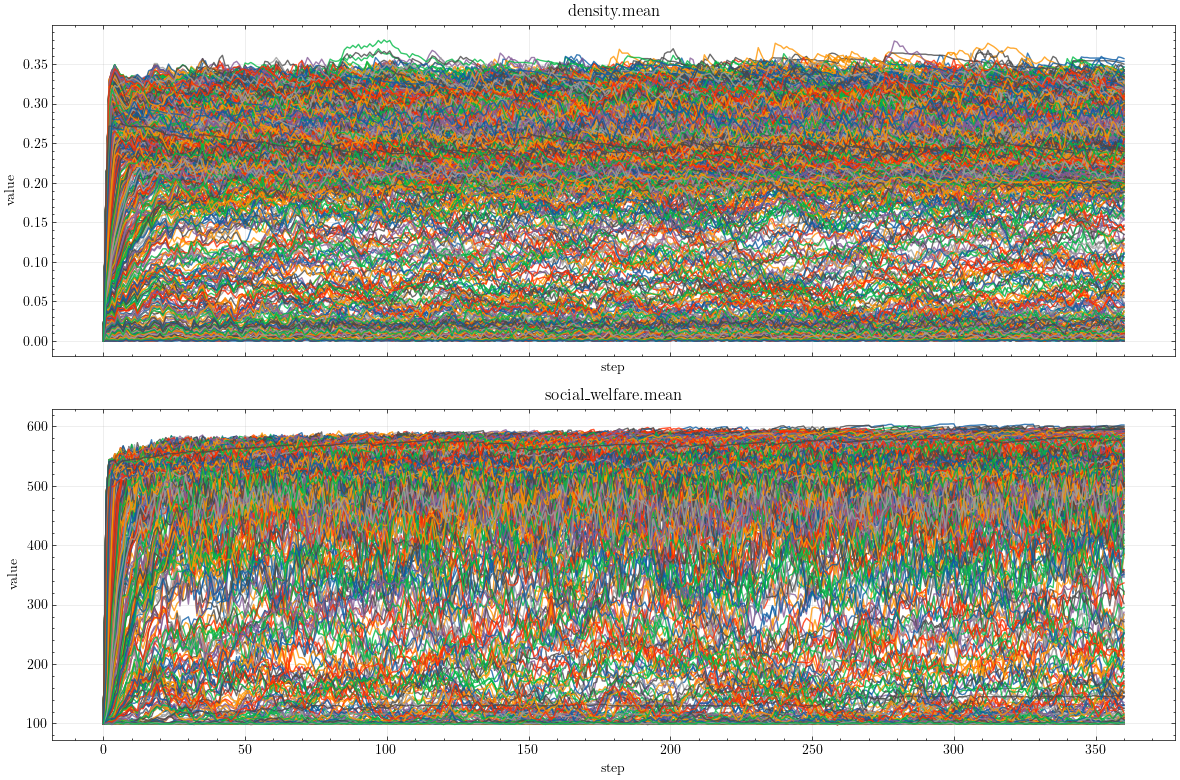

In [12]:
timeseries = output_group["tensors"].get("timeseries")

if timeseries is None:
    print("No time-series tensor available for this policy.")
else:
    observable_labels = tuple(output_group["labels"]["observable"])
    sample_labels = np.asarray(output_group["labels"]["sample"])
    step_labels = np.asarray(output_group["labels"]["step"])

    n_plots = len(observable_labels)
    fig, axes = plt.subplots(n_plots, 1, figsize=(12, 4 * n_plots), sharex=True)
    axes = np.atleast_1d(axes)

    for axis, observable_index in zip(axes, range(n_plots), strict=True):
        observable_name = observable_labels[observable_index]
        for row_index, sample_label in enumerate(sample_labels):
            axis.plot(
                step_labels,
                timeseries[row_index, observable_index],
                alpha=0.8,
                label=f"sample {int(sample_label)}",
            )
        axis.set_title(observable_name)
        axis.set_xlabel("step")
        axis.set_ylabel("value")
        axis.grid(alpha=0.3)
        if len(sample_labels) <= 10:
            axis.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

    plt.tight_layout()
    plt.show()


## Final-step pair plots

This cell uses `outputs["tensors"]["final"]` for the metric values and colors the pair plots by one observable at a time.


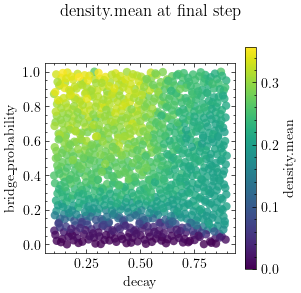

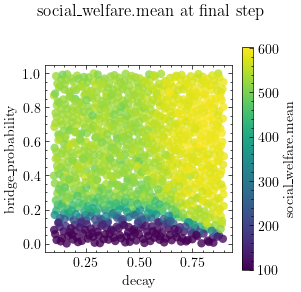

In [13]:
parameters = input_group["tensors"].get("parameters")
final = output_group["tensors"]["final"]
parameter_labels = tuple(input_group["labels"].get("parameter", ()))

if parameters is None:
    print("Pair plots require at least two varying parameters.")
else:
    parameter_spreads = np.ptp(np.asarray(parameters, dtype=float), axis=0)
    varying_parameter_indices = [
        parameter_index
        for parameter_index, parameter_spread in enumerate(parameter_spreads)
        if not np.isclose(parameter_spread, 0.0)
    ]
    varying_parameter_labels = tuple(
        parameter_labels[parameter_index]
        for parameter_index in varying_parameter_indices
    )

    if len(varying_parameter_indices) < 2:
        print("Pair plots require at least two varying parameters.")
    else:
        observable_labels = tuple(output_group["labels"]["observable"])
        varying_parameter_values = [
            np.asarray(parameters[:, parameter_index], dtype=float)
            for parameter_index in varying_parameter_indices
        ]
        parameter_pairs = [
            (column_index, row_index)
            for row_index in range(1, len(varying_parameter_labels))
            for column_index in range(row_index)
        ]
        panel_count = len(parameter_pairs)
        column_count = int(np.ceil(np.sqrt(panel_count)))
        row_count = int(np.ceil(panel_count / column_count))
        cmap = plt.get_cmap("viridis")

        for observable_index, observable_name in enumerate(observable_labels):
            metric_values = np.asarray(final[:, observable_index], dtype=float)
            color_min = float(metric_values.min())
            color_max = float(metric_values.max())
            if color_min == color_max:
                color_max = color_min + 1e-9
            norm = Normalize(vmin=color_min, vmax=color_max)

            figure, axes = plt.subplots(
                row_count,
                column_count,
                figsize=(3 * column_count, 3 * row_count),
                constrained_layout=True,
                squeeze=False,
            )
            flat_axes = axes.ravel()

            for axis, (x_index, y_index) in zip(flat_axes, parameter_pairs):
                axis.scatter(
                    varying_parameter_values[x_index],
                    varying_parameter_values[y_index],
                    c=metric_values,
                    cmap=cmap,
                    norm=norm,
                    alpha=0.8,
                    linewidths=0,
                )
                axis.set_box_aspect(1)
                axis.set_xlabel(varying_parameter_labels[x_index])
                axis.set_ylabel(varying_parameter_labels[y_index])

            for axis in flat_axes[panel_count:]:
                figure.delaxes(axis)

            figure.suptitle(f"{observable_name} at final step")
            scalar_mappable = ScalarMappable(norm=norm, cmap=cmap)
            scalar_mappable.set_array(metric_values)
            figure.colorbar(
                scalar_mappable,
                ax=flat_axes[:panel_count].tolist(),
                label=observable_name,
                shrink=0.85,
            )
            plt.show()


## Failure rows

If the task recorded failures, this cell shows the raw arrays stored under the `failures/` group.


In [14]:
failure_arrays if failure_arrays else "No stored failures."


{'input_label': array([], dtype='<U1024'),
 'durations_ms': array([], dtype=float64),
 'input_index': array([], dtype=int64),
 'error': array([], dtype='<U4096')}